In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [3]:
# Load MNIST dataset
(x_train, _), (x_test, _) = mnist.load_data()

In [4]:
# Normalize images
x_train = x_train.astype("float32") / 255.0

x_test = x_test.astype("float32") / 255.0

In [5]:
# Flatten images
x_train = x_train.reshape(-1, 784)

x_test = x_test.reshape(-1, 784)

In [6]:
# Add noise to images
noise_factor = 0.4

x_train_noisy = x_train + noise_factor * np.random.normal(
    0.0, 1.0, x_train.shape
)

x_test_noisy = x_test + noise_factor * np.random.normal(
    0.0, 1.0, x_test.shape
)

In [7]:
# Clip values between 0 and 1
x_train_noisy = np.clip(x_train_noisy, 0.0, 1.0)

x_test_noisy = np.clip(x_test_noisy, 0.0, 1.0)

In [8]:
# Build autoencoder
input_img = Input(shape=(784,))

# Encoder
encoded = Dense(128, activation="relu")(input_img)

encoded = Dense(64, activation="relu")(encoded)

# Decoder
decoded = Dense(128, activation="relu")(encoded)

decoded = Dense(784, activation="sigmoid")(decoded)

In [9]:
# Create and compile model
autoencoder = Model(input_img, decoded)

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

In [10]:
# Train using noisy images as input and clean images as target
autoencoder.fit(
    x_train_noisy,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_noisy, x_test)
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2412 - val_loss: 0.1747
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.1573 - val_loss: 0.1438
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.1388 - val_loss: 0.1319
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.1295 - val_loss: 0.1249
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1241 - val_loss: 0.1210
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.1204 - val_loss: 0.1174
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.1174 - val_loss: 0.1152
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.1151 - val_loss: 0.1132
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1132 - val_loss: 0.1116
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1117 - val_loss: 0.1105


In [11]:
# Denoise images
denoised_imgs = autoencoder.predict(x_test_noisy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


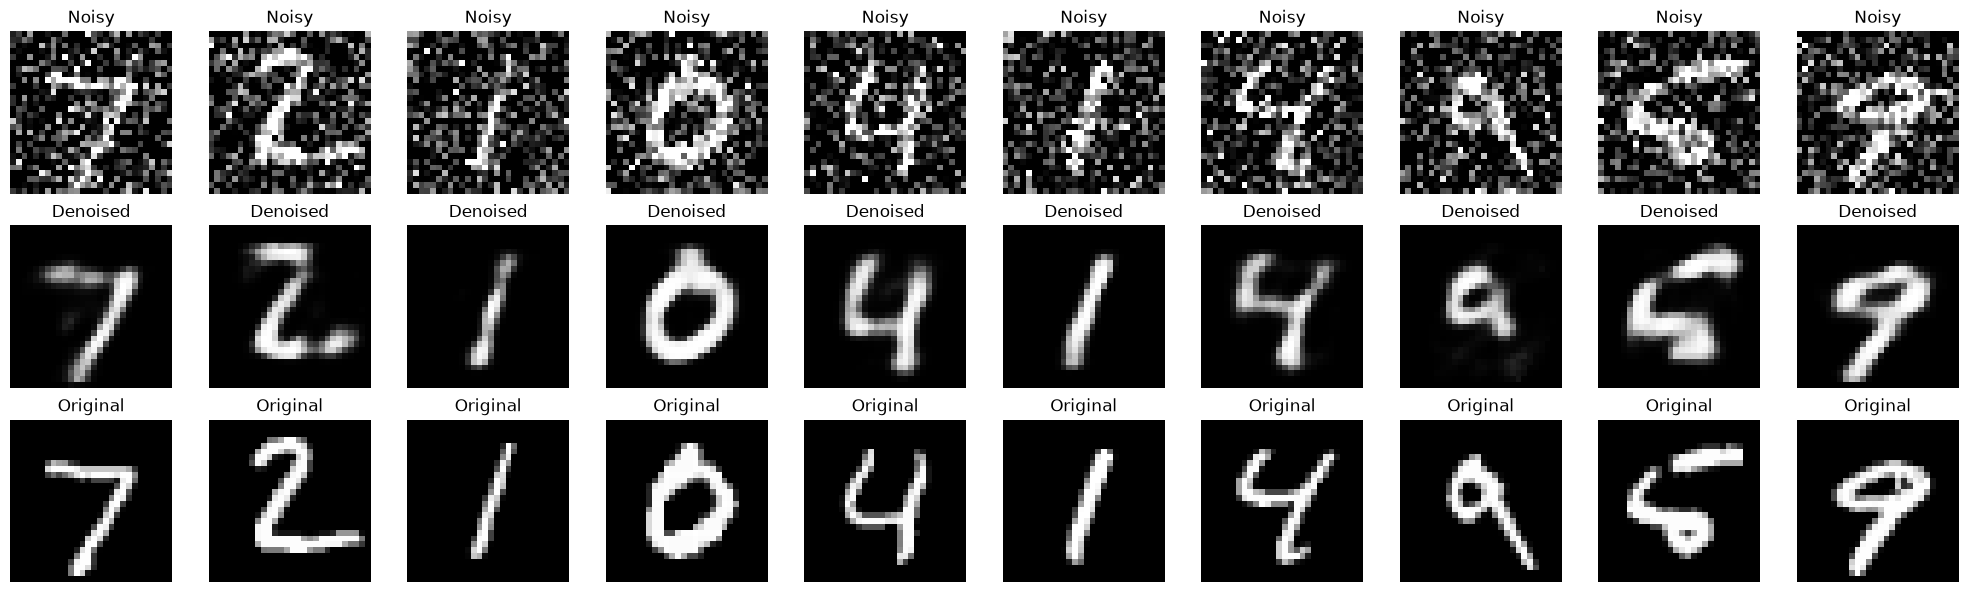

In [12]:
# Display noisy, denoised and original images
n = 10

plt.figure(figsize=(20, 6))

for i in range(n):

    plt.subplot(3, n, i + 1)
    plt.imshow(x_test_noisy[i].reshape(28, 28), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    plt.subplot(3, n, i + 1 + n)
    plt.imshow(denoised_imgs[i].reshape(28, 28), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")

    plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

plt.tight_layout()
plt.show()